# The maths behind Linear Regression

From "we want a smaller loss" to the two numbers that tell us how to get there:
$\frac{d\,\text{loss}}{da}$ and $\frac{d\,\text{loss}}{db}$.

# Setup

In [ ]:
%matplotlib widget

import matplotlib
import numpy as np
import matplotlib.pyplot as plt
import random
import matplotlib.colors as mcolors
from ipywidgets import interact, widgets, interactive, fixed, interact_manual
import random
import matplotlib.colors as mcolors
import time
import colorama
import pickle

with open("Teach_linear_regression.pkl", "rb") as f:
    (
        x, y, COEF_A, COEF_B,
        COEF_A_MIN, COEF_A_MAX,
        COEF_B_MIN, COEF_B_MAX,
        WORST_A_PARAM, WORST_B_PARAM,
        MIN_COST, MAX_COST,
        MIN_VALUE, MAX_VALUE, NB_ELEMENTS,
    ) = pickle.load(f)

In [ ]:
def get_df_by_dx(f, x, h):
    return (f(x + h) - f(x - h)) / (2 * h)

def plot_function_with_derivative(f, x_point=1, h=0.5, plot_triangle=False, plot_df_by_dx=False, fig=None, ylim=(-2, 4), formula=None):
    # Generate points for plotting
    MINIMUM_Y = ylim[0]
    x = np.linspace(-1, 3, 1000)
    y = f(x)

    # Create the plot with twin axes
    if fig is None:
        fig, ax1 = plt.subplots(figsize=(12, 6))
    else:
        # Handed a figure: redraw inside it instead of opening another canvas.
        fig.clear()
        ax1 = fig.add_subplot()
    ax2 = ax1.twinx() if plot_df_by_dx else None

    if plot_df_by_dx:
        # Plot derivative on second axis
        df_by_dx = get_df_by_dx(f, x, h)
        # Split into positive and negative parts
        pos_mask = df_by_dx > 0
        neg_mask = ~pos_mask

        # print(f"{x.shape = }")
        # print(f"{df_by_dx.shape = }")
        # print(f"{x[pos_mask].shape = }")
        # print(f"{df_by_dx[pos_mask].shape = }")
        # print(f"{x[neg_mask].shape = }")
        # print(f"{df_by_dx[neg_mask].shape = }")

        # Plot positive values in green
        ax2.scatter(x[pos_mask], df_by_dx[pos_mask], c='g', marker='.', label="f'(x) > 0", alpha=0.25)
        # Plot negative values in red
        ax2.scatter(x[neg_mask], df_by_dx[neg_mask], c='r', marker='.', label="f'(x) < 0", alpha=0.25)

        # A constant derivative is constant only up to float noise. Left alone the twin
        # axis zooms into that noise and prints a 1e-12 offset, which reads as a bug.
        if np.ptp(df_by_dx) < 1e-6:
            centre = float(np.mean(df_by_dx))
            ax2.set_ylim(centre - 1, centre + 1)

        ax2.set_ylabel(r"$\frac{df(x)}{dx}$", color="g")
        ax2.tick_params(axis='y', labelcolor="g")

    # Plot main function on first axis
    ax1.plot(x, y, "black", label="f(x)", alpha=0.5)
    if formula is not None:
        # "black" at alpha 0.5 on white is exactly "gray", so the formula, the curve
        # and the left axis all read as the same thing.
        ax1.text(0.02, 0.96, rf"$f(x) = {formula}$", transform=ax1.transAxes,
                 va="top", color="gray", fontsize=13)
    # Calculate points for derivative visualization
    x_plus_h = x_point + h
    x_minus_h = x_point - h
    y_point = f(x_point)
    y_plus_h = f(x_plus_h)
    y_minus_h = f(x_minus_h)

    # Plot points
    ax1.plot(
        x_point, y_point, "X", color="orange", label=f"f({x_point:.2f})", markersize=10
    )
    ax1.plot([x_point, x_point], [MINIMUM_Y, y_point], color="orange", alpha=0.5)

    if plot_triangle:
        ax1.plot(x_point + h, y_plus_h, "+", color="gray", alpha=0.5, markersize=8)
        ax1.plot(x_point - h, y_minus_h, "+", color="gray", alpha=0.5, markersize=8)

        # Plot secant line through the two points
        x_line = np.array([x_point - h, x_point + h])
        y_line = np.array([y_minus_h, y_plus_h])
        ax1.plot(x_line, y_line, "-", color="purple", linewidth=2)

        top_horizontal_line_x = np.array([x_minus_h, x_plus_h])
        top_horizontal_line_y = np.array([y_plus_h, y_plus_h])

        left_vertical_line_x = np.array([x_minus_h, x_minus_h])
        left_vertical_line_y = np.array([y_minus_h, y_plus_h])

        h_minus_gray_line_x = np.array([x_minus_h, x_minus_h])
        h_minus_gray_line_y = np.array([-10, y_minus_h])

        h_plus_gray_line_x = np.array([x_plus_h, x_plus_h])
        h_plus_gray_line_y = np.array([-10, y_plus_h])

        # Add text annotations for dy and dx with their values
        dy = y_plus_h - y_minus_h
        dx = x_plus_h - x_minus_h
        derivative = dy / dx

        # Using matplotlib's text with math mode and custom colors
        ax1.text(0.02, 0.885, r"$\mathbf{dy} = " + f"{dy:.2f}$", transform=ax1.transAxes,
                 va="top", color="red", fontsize=12)
        ax1.text(
            0.02,
            0.818,
            r"$\mathbf{dx} = " + r" 2 \times h " + f" = {dx:.2f} " + "$",
            transform=ax1.transAxes,
            va="top",
            color="blue",
            fontsize=12,
        )

        # Add the ratio calculation with colored values and result
        ax1.text(
            0.02,
            0.701,
            r"$\mathbf{"
            + r"\frac{dy}{dx} = "
            + r"\frac{"
            + f"{dy:.2f}"
            + "}{"
            + f"{dx:.2f}"
            + "}} = "
            + f"{derivative:.2f}$",
            transform=ax1.transAxes,
            va="top",
            color="purple",
            fontsize=14,
        )

        ax1.text(
            top_horizontal_line_x[0],
            top_horizontal_line_y[0] + 0.1,
            r"$\mathbf{dx} = 2 h$",
            color="blue",
            fontsize=12,
        )
        ax1.plot(
            top_horizontal_line_x,
            top_horizontal_line_y,
            "-",
            color="blue",
            linewidth=2,
            label="$dx = 2 h$",
        )
        ax1.plot(
            left_vertical_line_x,
            left_vertical_line_y,
            "-",
            color="red",
            linewidth=2,
            label=r"$dy = \frac{f(x+h) - f(x-h)}{2h}$",
        )
        ax1.plot(
            h_minus_gray_line_x,
            h_minus_gray_line_y,
            ":",
            color="gray",
            linewidth=2,
            label="x-h",
        )
        ax1.plot(
            h_plus_gray_line_x,
            h_plus_gray_line_y,
            ":",
            color="gray",
            linewidth=2,
            label="x+h",
        )

        ax1.text(x_plus_h + 0.05, MINIMUM_Y + 0.5, r"x+h", color="gray", fontsize=12)
        ax1.text(x_minus_h - 0.15, MINIMUM_Y + 0.5, r"x-h", color="gray", fontsize=12)

    ax1.grid(True)
    ax1.set_title(f"Function with Derivative Approximation (h={h:.2f})")
    ax1.set_xlabel("x")
    ax1.set_ylabel("f(x)", color="gray")
    ax1.tick_params(axis='y', labelcolor="gray")

    ax1.set_xlim(-1, 3)
    ax1.set_ylim(*ylim)


def chaotic_function(x):
    return (
        np.sin(5 * x**2) * np.cos(x / 2)
        + np.exp(-((x - 3) ** 2) / 10) * np.sin(5 * x)
        + 0.5 * np.tanh(x / 2)
    )

In [ ]:
# ---------------------------- Linear regression ----------------------------- #
def predict(x, a, b):
    return a * x + b

def get_cost(y, y_hat):
    return ((y - y_hat) ** 2).sum()

def get_gradients(x, y, a, b):
    """dloss/da and dloss/db for loss = sum((a*x + b - y)^2)."""
    error = predict(x, a, b) - y
    return (2 * error * x).sum(), (2 * error).sum()

# The cost surface, computed once: this is the landscape every later plot sits on.
A_GRID, B_GRID = np.meshgrid(np.linspace(COEF_A_MIN, COEF_A_MAX, 60),
                             np.linspace(COEF_B_MIN, COEF_B_MAX, 60))
COST_GRID = np.array([[get_cost(y, predict(x, a, b)) for a in A_GRID[0]] for b in B_GRID[:, 0]])
print(f"{NB_ELEMENTS} points | best a={COEF_A:.2f} b={COEF_B:.2f} | cost there = {get_cost(y, predict(x, COEF_A, COEF_B)):.0f}")

100 points | best a=2.16 b=2.28 | cost there = 31


# Hook

For our $a x + b$, we want to **minimize the loss**.

A really powerful tool would be $\dfrac{d\,\text{loss}}{da}$ and $\dfrac{d\,\text{loss}}{db}$. Why?

> Because a derivative tells us **how much the cost moves when we change a weight**.
>
> Computing it therefore tells us **how to update our weights**, and iterate towards a smaller loss.

interactive(children=(Checkbox(value=False, description='Cost surface'), FloatSlider(value=0.6, description='a…

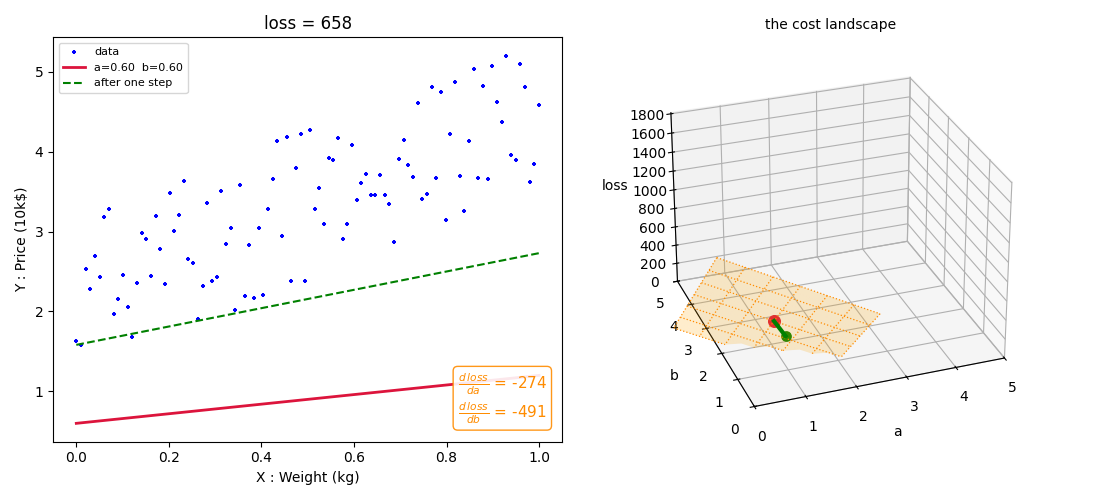

In [ ]:
# The figure is built ONCE here, outside the callback, and every update redraws into it.
fig = plt.figure(figsize=(11, 5))
ax_fit = fig.add_subplot(1, 2, 1)
ax_3d = fig.add_subplot(1, 2, 2, projection="3d")

@interact(
    show_surface=widgets.Checkbox(value=False, description="Cost surface"),
    a=widgets.FloatSlider(value=0.6, min=COEF_A_MIN, max=COEF_A_MAX, step=0.05, description="a:"),
    b=widgets.FloatSlider(value=0.6, min=COEF_B_MIN, max=COEF_B_MAX, step=0.05, description="b:"),
    learning_rate=widgets.FloatLogSlider(value=2e-3, base=10, min=-4, max=-2.2, step=0.05,
                                         description="lr:", readout_format=".4f"),
)
def gradient_in_3d(show_surface, a, b, learning_rate):
    # Same pattern as notebook 2: reuse the figure, clear the axes. Creating a new
    # figure inside the callback is what stacks a fresh plot under every slider move.
    ax_fit.clear()
    ax_3d.clear()
    cost = get_cost(y, predict(x, a, b))
    d_a, d_b = get_gradients(x, y, a, b)

    # One gradient step: this is the arrow, and the whole point of the notebook.
    a_next, b_next = a - learning_rate * d_a, b - learning_rate * d_b
    cost_next = get_cost(y, predict(x, a_next, b_next))

    # Left: the line this (a, b) draws through the data.
    ax_fit.scatter(x, y, c="b", s=6, marker="+", label="data")
    ax_fit.plot(x, predict(x, a, b), c="crimson", lw=2, label=f"a={a:.2f}  b={b:.2f}")
    ax_fit.plot(x, predict(x, a_next, b_next), c="green", lw=1.5, ls="--", label="after one step")
    ax_fit.set_xlabel("X : Weight (kg)"); ax_fit.set_ylabel("Y : Price (10k$)")
    ax_fit.set_title(f"loss = {cost:.0f}"); ax_fit.legend(loc="upper left", fontsize=8)

    # Right: the same (a, b) on the cost landscape.
    if show_surface:
        ax_3d.plot_surface(A_GRID, B_GRID, COST_GRID, cmap="winter", alpha=0.35,
                           linewidth=0, antialiased=True)

    # The tangent plane: the local linear approximation the derivatives give us.
    # Kept small - the slope here is in the hundreds, so a wide patch would shoot off the axes.
    span, step = 1.5, 0.25
    ticks = np.arange(-span, span + step / 2, step)
    pa, pb = np.meshgrid(a + ticks, b + ticks)
    plane = cost + d_a * (pa - a) + d_b * (pb - b)
    plane[(plane < 0) | (plane > MAX_COST)] = np.nan      # mask, never distort
    ax_3d.plot_surface(pa, pb, plane, color="orange", alpha=0.2, linewidth=0, shade=False)
    # A dotted grid every 0.5 in a and in b. A flat orange wash gives the eye nothing to
    # measure the tilt against; evenly spaced lines do, and they stay readable through it.
    ax_3d.plot_wireframe(pa, pb, plane, rstride=2, cstride=2,
                         color="darkorange", linewidths=0.9, linestyles=":")

    # The step, drawn as a segment rather than a quiver: a 3D quiver with a z-component in the
    # hundreds escapes the axes box and reads as a bar across the whole figure.
    ax_3d.plot([a, a_next], [b, b_next], [cost, cost_next], c="green", lw=3, zorder=6)
    ax_3d.scatter(a_next, b_next, cost_next, c="green", s=45, marker="o", depthshade=False, zorder=7)
    ax_3d.scatter(a, b, cost, c="crimson", s=70, depthshade=False, zorder=8)

    ax_3d.set_xlim(COEF_A_MIN, COEF_A_MAX); ax_3d.set_ylim(COEF_B_MIN, COEF_B_MAX)
    ax_3d.set_zlim(0, MAX_COST)
    # Default view chosen so the tangent plane reads as a plane; drag to rotate.
    ax_3d.view_init(elev=28, azim=-110)
    ax_3d.set_xlabel("a"); ax_3d.set_ylabel("b")
    ax_3d.set_zlabel("loss", labelpad=8)
    ax_3d.set_title("the cost landscape", fontsize=10)
    ax_fit.text(0.97, 0.04, f"$\\frac{{d\\,loss}}{{da}}$ = {d_a:,.0f}\n"
                            f"$\\frac{{d\\,loss}}{{db}}$ = {d_b:,.0f}",
                transform=ax_fit.transAxes, fontsize=11, color="darkorange",
                ha="right", va="bottom",
                bbox=dict(boxstyle="round", fc="white", ec="darkorange", alpha=0.9))
    fig.tight_layout()
    fig.canvas.draw_idle()
    print(f"one step at lr={learning_rate:.4f}:  a {a:.2f} -> {a_next:.2f}   "
          f"b {b:.2f} -> {b_next:.2f}   loss {cost:.0f} -> {cost_next:.0f}")

The orange plane is what the two derivatives know: **the slope of the landscape right here**.
The green arrow is one step down it.

# But what is a derivative ?

Move the point, then shrink $h$.

interactive(children=(ToggleButtons(description='f(x):', index=1, options=('x + c', 'a·x', 'x²', 'chaotic'), v…

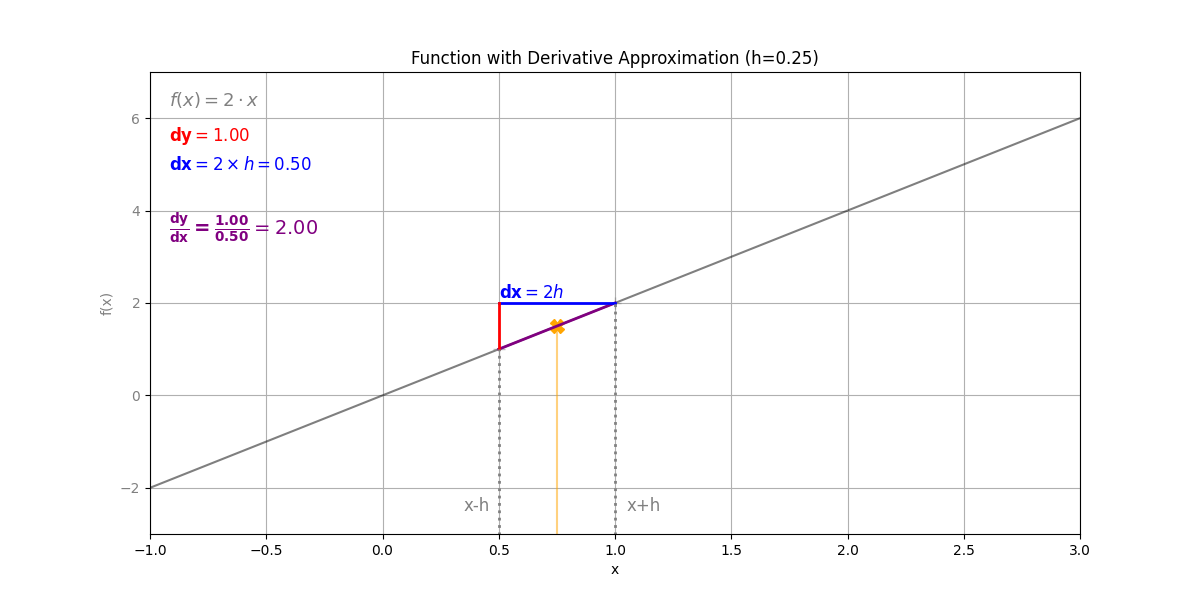

In [ ]:
# One figure for this demo too. The notebook stays on %matplotlib widget all the way
# through: switching to inline here makes the inline backend close every open figure
# at the end of the first cell that draws, which silently kills the 3D hook above.
fd_fig = plt.figure(figsize=(12, 6))

# The shapes the toolkit covers, each with the window that frames it over x in [-1, 3].
# A kink is worth a detour one day, the derivative does not exist at x = 1:
#     lambda x: np.where(x < 1, 2 * x, x / 2)
FUNCTIONS = {
    "x + c": (lambda x: x + 1, (-1, 5), r"x + 1"),
    "a·x": (lambda x: 2 * x, (-3, 7), r"2 \cdot x"),
    "x²": (lambda x: x ** 2, (-1, 10), r"x^{2}"),
    "chaotic": (chaotic_function, (-2, 4),
                r"\sin(5x^{2})\cos(x/2)"
                r" + e^{-(x-3)^{2}/10}\sin(5x)"
                r" + 0.5\tanh(x/2)"),
}

@interact(
    function=widgets.ToggleButtons(
        options=list(FUNCTIONS),
        value="a·x",
        description="f(x):",
    ),
    x_point=widgets.FloatSlider(
        value=0.75,
        min=0.0,
        max=2.0,
        step=0.01,
        description="X:",
    ),
    h=widgets.FloatSlider(
        value=0.25,
        min=0.01,
        max=0.5,
        step=0.01,
        description="h:",
    ),
    plot_triangle=widgets.Checkbox(
        value=True,
        description="Plot triangle",
    ),
    plot_df_by_dx=widgets.Checkbox(
        value=False,
        description="Plot df/dx",
    ),
)
def interactive_derivative(function, x_point, h, plot_triangle, plot_df_by_dx):
    f, ylim, formula = FUNCTIONS[function]
    plot_function_with_derivative(f, x_point, h, plot_triangle, plot_df_by_dx,
                                  fig=fd_fig, ylim=ylim, formula=formula)
    fd_fig.canvas.draw_idle()

# AJOUTER L'ANGLE

### $\frac{df(x)}{dx} = \lim_{h \to 0} \frac{f(x+h) - f(x-h)}{2h}$

To be **infinitely precise**, $h$ needs to be **infinitely small**. That is what the limit says,
and what a formula gives us for free.

<details>
<summary><b>Formal demonstration &mdash; <i>f(x) = ax</i></b></summary>

$$
\begin{aligned}
\frac{d}{dx}[ax]
  &= \lim_{h \to 0} \frac{a(x+h) - a(x-h)}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{ax + ah - ax + ah}{2h} \\[4pt]
  &= \lim_{h \to 0} \frac{2ah}{2h} \\[4pt]
  &= a
\end{aligned}
$$

</details>

# The toolkit we need

![](./data/derivative_draw_0_high_level.jpg)

$$
\color{#56D4F5}{\text{loss}}
= \Big(\;
\color{#FFB454}{a} \cdot \color{#7EE787}{x}
+ \color{#FFB454}{b}
\;-\; \color{#7EE787}{y} \;\Big)^{2}
$$

Add, multiply, power, constant, and the chain rule.

| | rule | example | derivative |
|---|---|---|---|
| **Constant** | $\dfrac{d}{dx}[c] = 0$ | $f(x) = -4$ | $0$ |
| **Multiply** | $\dfrac{d}{dx}[ax] = a$ | $f(x) = 2x$ | $2$ |
| **Add** | $\dfrac{d}{dx}[x+c] = 1$ | $f(x) = x+5$ | $1$ |
| **Power** | $\dfrac{d}{dx}[x^n] = n \cdot x^{n-1}$ | $f(x) = x^3$ | $3x^2$ |

<details>
<summary><b>Cheat sheet</b></summary>
<br>
<img src="./data/derivatives_cheat_sheet.png" alt="Derivatives cheat sheet" width="420">
</details>

## Chain rule

Because it lets us **derivate a complex formula by breaking it into simple ones**.

$$f(x) = \color{#FFB454}{5 \cdot} \color{#7EE787}{x^2} \color{#56D4F5}{+\, 3}$$

$$
\qquad
$$
$$
\color{#7EE787}{f_1(x) = x^2 = y_1}
$$
$$
\color{#FFB454}{f_2(y_1) = 5 \cdot y_1 = y_2}
$$
$$
\color{#56D4F5}{f_3(y_2) = y_2 + 3 = y}
$$

$$
\qquad
$$
$$
x \rightarrow \color{#7EE787}{[\,f_1\,]} \rightarrow y_1
  \rightarrow \color{#FFB454}{[\,f_2\,]} \rightarrow y_2
  \rightarrow \color{#56D4F5}{[\,f_3\,]} \rightarrow y
$$

### Intuition

Every box asks the same question: **how does my output move when my input moves?**

$$\frac{d_{\text{out}}}{d_{\text{in}}}$$

And the change is carried along the chain, so the derivatives multiply, and the intermediates cancel:

$$
\frac{df(x)}{dx}
= \frac{\cancel{dy_1}}{dx} \cdot \frac{\bcancel{dy_2}}{\cancel{dy_1}} \cdot \frac{dy}{\bcancel{dy_2}}
$$

$$\boxed{\;\frac{d}{dx}\big[f(g(x))\big] = \frac{df}{dg} \cdot \frac{dg}{dx}\;}$$

<details>
<summary><b>Demonstration &mdash; solving the example</b></summary>

| piece | rule | derivative |
|---|---|---|
| $f_1(x) = x^2$ | $\frac{d}{dx}[x^n] = n x^{n-1}$ | $\frac{df_1}{dx} = 2x$ |
| $f_2(y_1) = 5 y_1$ | $\frac{d}{dx}[ax] = a$ | $\frac{df_2}{dy_1} = 5$ |
| $f_3(y_2) = y_2 + 3$ | $\frac{d}{dx}[x+c] = 1$ | $\frac{df_3}{dy_2} = 1$ |

$$\frac{df(x)}{dx} = 2x \cdot 5 \cdot 1 = 10x$$

</details>

# Applying it to our Linear Regression

$$
\color{#56D4F5}{\text{loss}}
= \Big(\;
\color{#FFB454}{a} \cdot \color{#7EE787}{x}
+ \color{#FFB454}{b}
\;-\; \color{#7EE787}{y} \;\Big)^{2}
$$

### GOAL : $\dfrac{d\,\color{#56D4F5}{\text{loss}}}{d\,\color{#FFB454}{a}}$ and $\dfrac{d\,\color{#56D4F5}{\text{loss}}}{d\,\color{#FFB454}{b}}$

### Break the problem down with the chain rule

![](./data/derivative_draw_1.jpg)

Each box of the drawing is one nested piece of the same formula:

$$
\color{#56D4F5}{\text{loss}} = \Bigg(
\overbrace{
  \underbrace{
    \underbrace{\color{#FFB454}{a} \cdot \color{#7EE787}{x}}_{\color{#56D4F5}{u}}
    + \color{#FFB454}{b}
  }_{\color{#56D4F5}{\hat{y}}}
  - \color{#7EE787}{y}
}^{\color{#56D4F5}{\Delta}}
\Bigg)^{2}
$$


For each step we can deduce $\frac{d\,\text{output}}{d\,\text{input}}$, and carry it on:

$$
\frac{d\text{loss}}{da} = \frac{d\text{loss}}{d\Delta} \cdot \frac{d\Delta}{d\hat{y}} \cdot \frac{d\hat{y}}{du} \cdot \frac{du}{da}
\qquad\qquad
\frac{d\text{loss}}{db} = \frac{d\text{loss}}{d\Delta} \cdot \frac{d\Delta}{d\hat{y}} \cdot \frac{d\hat{y}}{db}
$$

![](./data/derivative_draw_2.jpg)

### Carry the $d\,\text{loss}$ back through the chain

![](./data/derivative_draw_3.jpg)

### Can you fill the missing derivatives?

Take two minutes on the drawing below before opening the reminder.


<details>
<summary><b>The four rules, again</b></summary>

| | rule |
|---|---|
| Constant | $\frac{d}{dx}[c] = 0$ |
| Multiply | $\frac{d}{dx}[ax] = a$ |
| Add | $\frac{d}{dx}[x+c] = 1$ |
| Power | $\frac{d}{dx}[x^n] = n \cdot x^{n-1}$ |

</details>

### Fill in each derivative with the toolkit

![](./data/derivative_draw_4.jpg)
